## 1: Environment Setup, Ingestion & Data Verification

In [1]:
import os
import sys
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    roc_curve,
    classification_report,
    confusion_matrix,
    fbeta_score,
    f1_score,
    precision_score,
    recall_score
)

# Plot styling configuration
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11
warnings.filterwarnings("ignore")


# Directory-Agnostic Path Resolver
def resolve_data_path(file_name: str) -> Path:
    candidates = [
        Path(f"data/{file_name}"),
        Path(f"../data/{file_name}"),
        Path.cwd() / "data" / file_name,
        Path.cwd().parent / "data" / file_name
    ]
    for p in candidates:
        if p.exists():
            return p.resolve()
    raise FileNotFoundError(f"Could not locate '{file_name}' in expected data/ paths.")

train_path = resolve_data_path("train_data.csv")
test_path = resolve_data_path("test_data.csv")

print(f"Loading training data from: {train_path}")
print(f"Loading test data from:     {test_path}")

df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

# Separate features and target
FEATURE_COLS = [c for c in df_train.columns if c != "Class"]
TARGET_COL = "Class"

X_train = df_train[FEATURE_COLS]
y_train = df_train[TARGET_COL]

X_test = df_test[FEATURE_COLS]
y_test = df_test[TARGET_COL]

# Ingestion Verification & Class Imbalance Audit
print("\n" + "=" * 60)
print("DATASET INGESTION & IMBALANCE SANITY CHECK")
print("=" * 60)
print(f"Features count:        {len(FEATURE_COLS)}")
print(f"Feature names (first 5 & last 5): {FEATURE_COLS[:5]} ... {FEATURE_COLS[-5:]}")
print("-" * 60)
print(f"Training set:          {X_train.shape[0]:,} rows × {X_train.shape[1]} cols")
print(f"  - Legitimate (0):    {(y_train == 0).sum():,} ({(y_train == 0).mean()*100:.3f}%)")
print(f"  - Fraudulent (1):    {(y_train == 1).sum():,} ({(y_train == 1).mean()*100:.3f}%)")
print("-" * 60)
print(f"Test set:              {X_test.shape[0]:,} rows × {X_test.shape[1]} cols")
print(f"  - Legitimate (0):    {(y_test == 0).sum():,} ({(y_test == 0).mean()*100:.3f}%)")
print(f"  - Fraudulent (1):    {(y_test == 1).sum():,} ({(y_test == 1).mean()*100:.3f}%)")
print("=" * 60)
print("Data ingestion and sanity verification complete.")


Loading training data from: E:\Fraud-Detection\data\train_data.csv
Loading test data from:     E:\Fraud-Detection\data\test_data.csv

DATASET INGESTION & IMBALANCE SANITY CHECK
Features count:        30
Feature names (first 5 & last 5): ['Amount', 'Time', 'V1', 'V2', 'V3'] ... ['V24', 'V25', 'V26', 'V27', 'V28']
------------------------------------------------------------
Training set:          226,980 rows × 30 cols
  - Legitimate (0):    226,602 (99.833%)
  - Fraudulent (1):    378 (0.167%)
------------------------------------------------------------
Test set:              56,746 rows × 30 cols
  - Legitimate (0):    56,651 (99.833%)
  - Fraudulent (1):    95 (0.167%)
Data ingestion and sanity verification complete.


## 2: Baseline Isolation Forest & Reusable Evaluation Framework

Training Baseline Isolation Forest (n_estimators=100, max_samples=1024, contamination=0.0017)...

BASELINE ISOLATION FOREST TEST PERFORMANCE
PR-AUC (North Star):       0.1557
ROC-AUC:                   0.9422
Recall (Fraud caught):     28.42% (27/95)
Precision:                 26.47%
F1-Score:                  0.2741
F2-Score:                  0.2801
False Alarms (FP):         75
Missed Frauds (FN):        68
Simulated Financial Loss:  $10,425.00


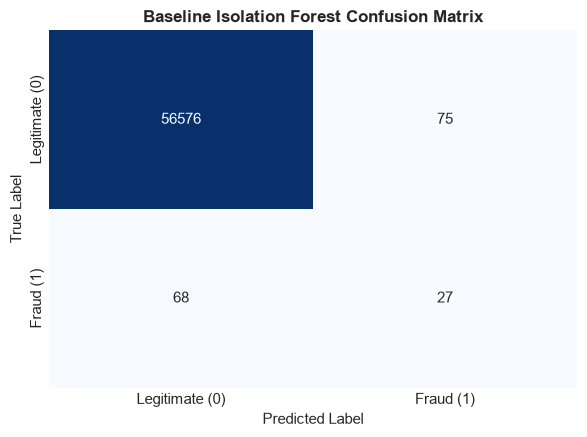

In [2]:
# Global leaderboard dictionary to store benchmarks
leaderboard_records = []

# Financial cost parameters defined in project architecture
COST_FN_USD = 150.0  # Cost per missed fraudulent transaction
COST_FP_USD = 3.0    # Operational friction/SMS challenge cost per false alarm


def evaluate_anomaly_detector(
    model,
    X_eval: pd.DataFrame,
    y_eval: pd.Series,
    model_name: str,
    custom_threshold: float = None,
    features_to_use: list = None
) -> dict:
    """Standardized evaluation for anomaly detectors on financial fraud data.
    
    In sklearn Isolation Forest:
    - Lower raw decision_function indicates an anomaly (outlier).
    - Inverted score (-decision_function) ensures higher values map to higher fraud probability.
    """
    X_input = X_eval[features_to_use] if features_to_use is not None else X_eval
    
    # Raw decision scores: higher negative value = deeper outlier
    raw_scores = model.decision_function(X_input)
    # Anomaly score: higher value = higher anomaly likelihood
    anomaly_scores = -raw_scores
    
    # Decision rule: either custom decision_function threshold or default predict()
    if custom_threshold is not None:
        y_pred = (raw_scores < custom_threshold).astype(int)
    else:
        # Default sklearn Isolation Forest decision rule: -1 is anomaly (Class 1), 1 is normal (Class 0)
        raw_pred = model.predict(X_input)
        y_pred = np.where(raw_pred == -1, 1, 0)
    
    # Calculate metrics
    pr_auc = average_precision_score(y_eval, anomaly_scores)
    roc_auc = roc_auc_score(y_eval, anomaly_scores)
    
    precision = precision_score(y_eval, y_pred, zero_division=0)
    recall = recall_score(y_eval, y_pred, zero_division=0)
    f1 = f1_score(y_eval, y_pred, zero_division=0)
    f2 = fbeta_score(y_eval, y_pred, beta=2, zero_division=0)
    
    tn, fp, fn, tp = confusion_matrix(y_eval, y_pred).ravel()
    financial_loss = (fn * COST_FN_USD) + (fp * COST_FP_USD)
    
    result = {
        "Model Configuration": model_name,
        "PR-AUC": round(pr_auc, 4),
        "ROC-AUC": round(roc_auc, 4),
        "Recall": f"{recall * 100:.2f}%",
        "Precision": f"{precision * 100:.2f}%",
        "F1-Score": round(f1, 4),
        "F2-Score": round(f2, 4),
        "Caught (TP)": int(tp),
        "Missed (FN)": int(fn),
        "False Alarms (FP)": int(fp),
        "Simulated Loss ($)": f"${financial_loss:,.2f}",
        "raw_scores": raw_scores,
        "anomaly_scores": anomaly_scores,
        "y_pred": y_pred
    }
    return result

print("Training Baseline Isolation Forest (n_estimators=100, max_samples=1024, contamination=0.0017)...")

baseline_iso = IsolationForest(
    n_estimators=100,
    max_samples=1024,
    contamination=0.0017,
    random_state=42,
    n_jobs=-1
)
baseline_iso.fit(X_train)

# Evaluate Baseline on Test Set
baseline_res = evaluate_anomaly_detector(
    model=baseline_iso,
    X_eval=X_test,
    y_eval=y_test,
    model_name="Baseline (n=100, s=1024, cont=0.0017)"
)

# Store in leaderboard
leaderboard_records.append({k: v for k, v in baseline_res.items() if k not in ["raw_scores", "anomaly_scores", "y_pred"]})

# Display baseline report
print("\n" + "=" * 65)
print("BASELINE ISOLATION FOREST TEST PERFORMANCE")
print("=" * 65)
print(f"PR-AUC (North Star):       {baseline_res['PR-AUC']}")
print(f"ROC-AUC:                   {baseline_res['ROC-AUC']}")
print(f"Recall (Fraud caught):     {baseline_res['Recall']} ({baseline_res['Caught (TP)']}/{baseline_res['Caught (TP)'] + baseline_res['Missed (FN)']})")
print(f"Precision:                 {baseline_res['Precision']}")
print(f"F1-Score:                  {baseline_res['F1-Score']}")
print(f"F2-Score:                  {baseline_res['F2-Score']}")
print(f"False Alarms (FP):         {baseline_res['False Alarms (FP)']:,}")
print(f"Missed Frauds (FN):        {baseline_res['Missed (FN)']:,}")
print(f"Simulated Financial Loss:  {baseline_res['Simulated Loss ($)']}")
print("=" * 65)

# Visualizing Baseline Confusion Matrix
cm = confusion_matrix(y_test, baseline_res["y_pred"])
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Legitimate (0)", "Fraud (1)"],
    yticklabels=["Legitimate (0)", "Fraud (1)"],
    ax=ax
)
ax.set_title("Baseline Isolation Forest Confusion Matrix", fontsize=12, fontweight="bold")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
plt.tight_layout()
plt.show()

## 3: Diagnostic Score Distribution & Separation Audit

DIAGNOSTIC AUDIT: SCORE DISTRIBUTIONS & SEPARATION
Legitimate Transactions (n=56,651):
  - Mean score:   -0.2851  | Median: -0.2950
  - 95th %ile:    -0.2225  | Max:    0.1403
-----------------------------------------------------------------
Fraudulent Transactions (n=95):
  - Mean score:   -0.0865  | Median: -0.0846
  - 5th %ile:     -0.2789  | Min:    -0.3083
-----------------------------------------------------------------
KS-Statistic (Separation Quality): 0.7831 (p-value: 2.70e-62)
Normal tx above Fraud Median:     375 (0.66% false-alarm risk)


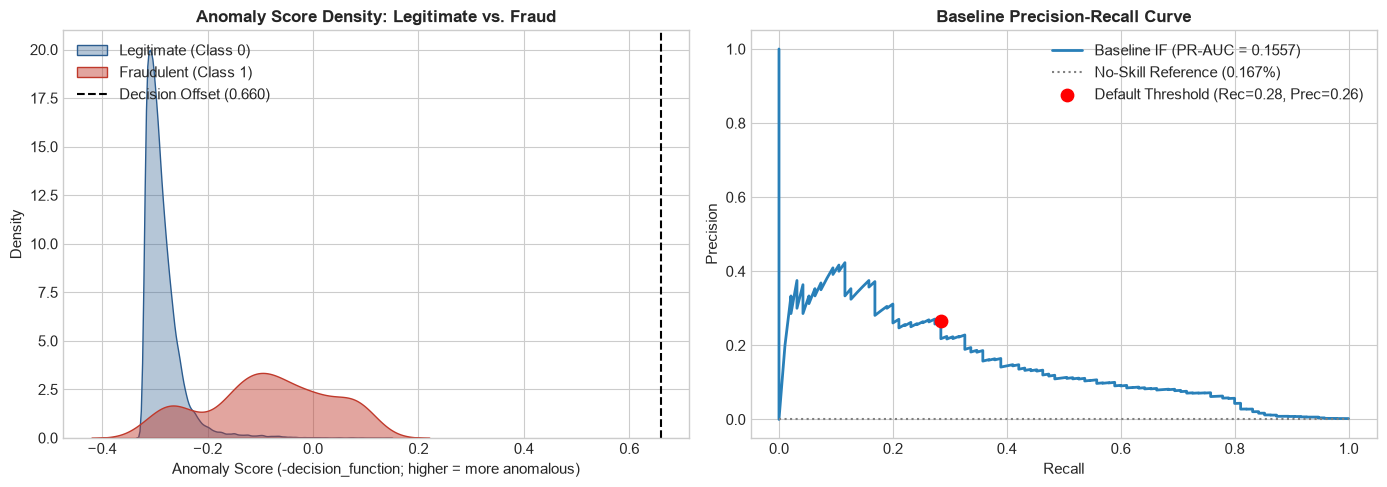

In [3]:
from scipy.stats import ks_2samp

# Extract test anomaly scores (-decision_function)
test_anomaly_scores = baseline_res["anomaly_scores"]
legit_scores = test_anomaly_scores[y_test == 0]
fraud_scores = test_anomaly_scores[y_test == 1]

# Kolmogorov-Smirnov test to quantify distributional separation
ks_stat, ks_pval = ks_2samp(legit_scores, fraud_scores)

print("=" * 65)
print("DIAGNOSTIC AUDIT: SCORE DISTRIBUTIONS & SEPARATION")
print("=" * 65)
print(f"Legitimate Transactions (n={len(legit_scores):,}):")
print(f"  - Mean score:   {legit_scores.mean():.4f}  | Median: {np.median(legit_scores):.4f}")
print(f"  - 95th %ile:    {np.percentile(legit_scores, 95):.4f}  | Max:    {legit_scores.max():.4f}")
print("-" * 65)
print(f"Fraudulent Transactions (n={len(fraud_scores):,}):")
print(f"  - Mean score:   {fraud_scores.mean():.4f}  | Median: {np.median(fraud_scores):.4f}")
print(f"  - 5th %ile:     {np.percentile(fraud_scores, 5):.4f}  | Min:    {fraud_scores.min():.4f}")
print("-" * 65)
print(f"KS-Statistic (Separation Quality): {ks_stat:.4f} (p-value: {ks_pval:.2e})")

# Overlap quantify: How many normal transactions score higher than the fraud median?
normal_above_fraud_median = (legit_scores >= np.median(fraud_scores)).sum()
print(f"Normal tx above Fraud Median:     {normal_above_fraud_median:,} ({normal_above_fraud_median/len(legit_scores)*100:.2f}% false-alarm risk)")
print("=" * 65)

# Diagnostic Visualizations: Score Density & PR-Curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. KDE Distribution of Anomaly Scores
sns.kdeplot(legit_scores, ax=ax1, label="Legitimate (Class 0)", color="#2b5c8f", fill=True, alpha=0.35, bw_adjust=0.8)
sns.kdeplot(fraud_scores, ax=ax1, label="Fraudulent (Class 1)", color="#c0392b", fill=True, alpha=0.45, bw_adjust=0.8)
ax1.axvline(x=-baseline_iso.offset_, color="black", linestyle="--", linewidth=1.5, label=f"Decision Offset ({ -baseline_iso.offset_:.3f})")
ax1.set_title("Anomaly Score Density: Legitimate vs. Fraud", fontsize=12, fontweight="bold")
ax1.set_xlabel("Anomaly Score (-decision_function; higher = more anomalous)")
ax1.set_ylabel("Density")
ax1.legend(loc="upper left")

# 2. Precision-Recall Curve
precisions, recalls, thresholds = precision_recall_curve(y_test, test_anomaly_scores)
ax2.plot(recalls, precisions, color="#2980b9", lw=2, label=f"Baseline IF (PR-AUC = {baseline_res['PR-AUC']})")
ax2.plot([0, 1], [0.00167, 0.00167], color="gray", linestyle=":", label="No-Skill Reference (0.167%)")
# Mark baseline operating point
base_prec = float(baseline_res["Precision"].replace("%", "")) / 100.0
base_rec = float(baseline_res["Recall"].replace("%", "")) / 100.0
ax2.scatter([base_rec], [base_prec], color="red", s=80, zorder=5, label=f"Default Threshold (Rec={base_rec:.2f}, Prec={base_prec:.2f})")

ax2.set_title("Baseline Precision-Recall Curve", fontsize=12, fontweight="bold")
ax2.set_xlabel("Recall")
ax2.set_ylabel("Precision")
ax2.set_ylim([-0.05, 1.05])
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

## 4: Unsupervised vs. Semi-Supervised Novelty Detection Benchmark

Semi-Supervised Normal Training Samples: 226,602 (100% legitimate)

Training Semi-Supervised Novelty Isolation Forest on Class 0 only...

PARADIGM COMPARISON: OUTLIER DETECTION VS. NOVELTY DETECTION


,Paradigm,PR-AUC,ROC-AUC,KS-Stat,Recall,Precision,F1-Score,Caught (TP),False Alarms (FP),Loss ($)
0,Unsupervised (All X_train),0.1557,0.9422,0.7831,28.42%,26.47%,0.2741,27,75,"$10,425.00"
1,Semi-Supervised (Class 0 only),0.1281,0.9422,0.7965,30.53%,22.31%,0.2578,29,101,"$10,203.00"


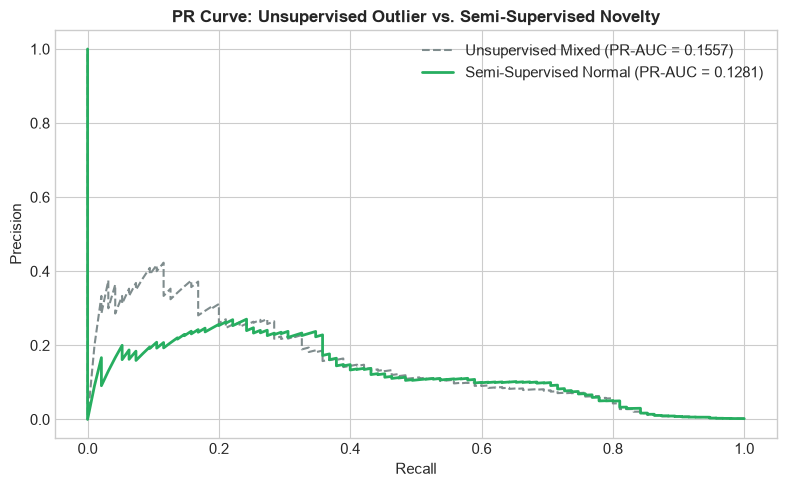

In [4]:
# 1. Filter pure legitimate data for Semi-Supervised Novelty Detection
X_train_normal = X_train[y_train == 0]
print(f"Semi-Supervised Normal Training Samples: {X_train_normal.shape[0]:,} (100% legitimate)")

# 2. Train Semi-Supervised Novelty Detector (Novelty Mode)
# When training on pure inliers, contamination='auto' or 0.0017 provides clean baseline
print("\nTraining Semi-Supervised Novelty Isolation Forest on Class 0 only...")
novelty_iso = IsolationForest(
    n_estimators=100,
    max_samples=1024,
    contamination=0.0017,
    random_state=42,
    n_jobs=-1
)
novelty_iso.fit(X_train_normal)

# 3. Evaluate Novelty Detector on Test Set
novelty_res = evaluate_anomaly_detector(
    model=novelty_iso,
    X_eval=X_test,
    y_eval=y_test,
    model_name="Novelty Detection (Class 0 only, s=1024)"
)

# Store in leaderboard
leaderboard_records.append({k: v for k, v in novelty_res.items() if k not in ["raw_scores", "anomaly_scores", "y_pred"]})

# 4. Comparative Score Distributions & KS-Stat
novelty_scores = novelty_res["anomaly_scores"]
novelty_legit = novelty_scores[y_test == 0]
novelty_fraud = novelty_scores[y_test == 1]
ks_novelty, _ = ks_2samp(novelty_legit, novelty_fraud)

print("\n" + "=" * 70)
print("PARADIGM COMPARISON: OUTLIER DETECTION VS. NOVELTY DETECTION")
print("=" * 70)
comparison_df = pd.DataFrame([
    {
        "Paradigm": "Unsupervised (All X_train)",
        "PR-AUC": baseline_res["PR-AUC"],
        "ROC-AUC": baseline_res["ROC-AUC"],
        "KS-Stat": round(ks_stat, 4),
        "Recall": baseline_res["Recall"],
        "Precision": baseline_res["Precision"],
        "F1-Score": baseline_res["F1-Score"],
        "Caught (TP)": baseline_res["Caught (TP)"],
        "False Alarms (FP)": baseline_res["False Alarms (FP)"],
        "Loss ($)": baseline_res["Simulated Loss ($)"]
    },
    {
        "Paradigm": "Semi-Supervised (Class 0 only)",
        "PR-AUC": novelty_res["PR-AUC"],
        "ROC-AUC": novelty_res["ROC-AUC"],
        "KS-Stat": round(ks_novelty, 4),
        "Recall": novelty_res["Recall"],
        "Precision": novelty_res["Precision"],
        "F1-Score": novelty_res["F1-Score"],
        "Caught (TP)": novelty_res["Caught (TP)"],
        "False Alarms (FP)": novelty_res["False Alarms (FP)"],
        "Loss ($)": novelty_res["Simulated Loss ($)"]
    }
])
display(comparison_df)
print("=" * 70)

# Compare PR Curves
prec_nov, rec_nov, _ = precision_recall_curve(y_test, novelty_scores)
plt.figure(figsize=(8, 5))
plt.plot(recalls, precisions, label=f"Unsupervised Mixed (PR-AUC = {baseline_res['PR-AUC']})", color="#7f8c8d", linestyle="--")
plt.plot(rec_nov, prec_nov, label=f"Semi-Supervised Normal (PR-AUC = {novelty_res['PR-AUC']})", color="#27ae60", linewidth=2)
plt.title("PR Curve: Unsupervised Outlier vs. Semi-Supervised Novelty", fontsize=12, fontweight="bold")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 5: Feature Subspace Optimization & Noise Pruning

TOP 15 ANOMALY-DISCRIMINATIVE FEATURES (TRAINING CORRELATION)
Rank  1:  V17      (Abs Pearson Correlation: 0.3207)
Rank  2:  V14      (Abs Pearson Correlation: 0.3016)
Rank  3:  V12      (Abs Pearson Correlation: 0.2547)
Rank  4:  V10      (Abs Pearson Correlation: 0.2116)
Rank  5:  V16      (Abs Pearson Correlation: 0.1903)
Rank  6:  V3       (Abs Pearson Correlation: 0.1889)
Rank  7:  V7       (Abs Pearson Correlation: 0.1810)
Rank  8:  V11      (Abs Pearson Correlation: 0.1521)
Rank  9:  V4       (Abs Pearson Correlation: 0.1297)
Rank 10:  V18      (Abs Pearson Correlation: 0.1071)
Rank 11:  V1       (Abs Pearson Correlation: 0.0976)
Rank 12:  V9       (Abs Pearson Correlation: 0.0957)
Rank 13:  V5       (Abs Pearson Correlation: 0.0920)
Rank 14:  V2       (Abs Pearson Correlation: 0.0875)
Rank 15:  V6       (Abs Pearson Correlation: 0.0447)
Fitting Isolation Forest on 'All 30 Features (Baseline)' (30 features)...
Fitting Isolation Forest on 'Top 6 Subspace' (6 features)...
Fitting 

,Feature Configuration,Features Used,PR-AUC,ROC-AUC,Recall,Precision,F1-Score,Caught (TP),False Alarms (FP),Loss ($)
0,All 30 Features (Baseline),30,0.1557,0.9422,28.42%,26.47%,0.2741,27,75,"$10,425.00"
1,Top 6 Subspace,6,0.5313,0.9353,53.68%,56.04%,0.5484,51,40,"$6,720.00"
2,Top 10 Subspace,10,0.5097,0.9397,52.63%,45.05%,0.4854,50,61,"$6,933.00"
3,Top 15 Subspace,15,0.4058,0.9337,40.00%,40.43%,0.4021,38,56,"$8,718.00"
4,All 30 (max_features=0.6),30,0.1582,0.9371,26.32%,25.25%,0.2577,25,74,"$10,722.00"


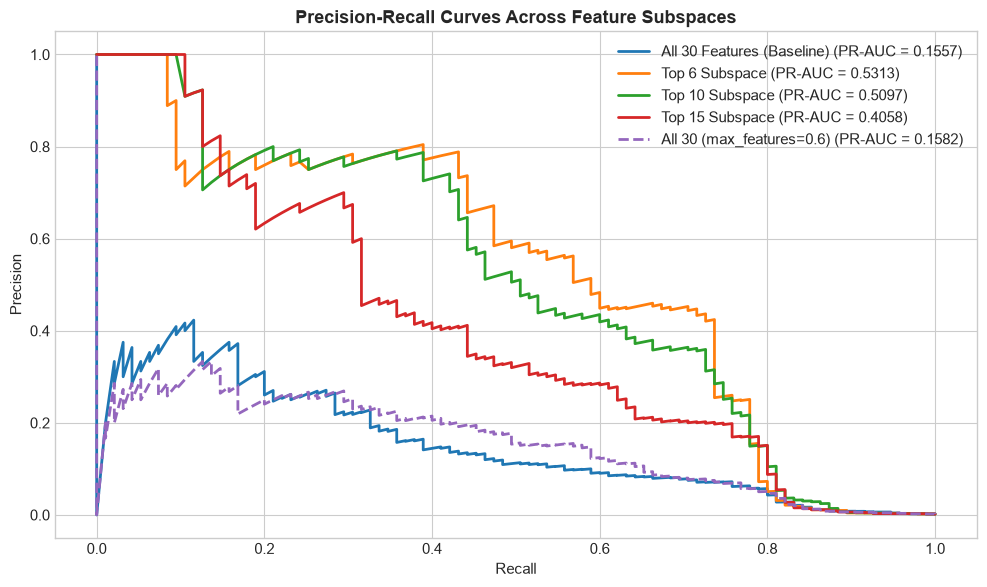

In [5]:
# 1. Feature Ranking via Statistical Anomaly Correlation on Training Data
train_corrs = X_train.corrwith(y_train).abs().sort_values(ascending=False)

print("=" * 65)
print("TOP 15 ANOMALY-DISCRIMINATIVE FEATURES (TRAINING CORRELATION)")
print("=" * 65)
for rank, (feat, val) in enumerate(train_corrs.head(15).items(), 1):
    print(f"Rank {rank:2d}:  {feat:<8} (Abs Pearson Correlation: {val:.4f})")
print("=" * 65)

# Define Candidate Subspaces
feature_subsets = {
    "All 30 Features (Baseline)": FEATURE_COLS,
    "Top 6 Subspace": train_corrs.head(6).index.tolist(),
    "Top 10 Subspace": train_corrs.head(10).index.tolist(),
    "Top 15 Subspace": train_corrs.head(15).index.tolist(),
}

# 2. Benchmark Feature Subspaces
subspace_results = []
plt.figure(figsize=(10, 6))

for name, feats in feature_subsets.items():
    print(f"Fitting Isolation Forest on '{name}' ({len(feats)} features)...")
    iso_sub = IsolationForest(
        n_estimators=100,
        max_samples=1024,
        contamination=0.0017,
        random_state=42,
        n_jobs=-1
    )
    iso_sub.fit(X_train[feats])
    
    res = evaluate_anomaly_detector(
        model=iso_sub,
        X_eval=X_test,
        y_eval=y_test,
        model_name=f"Subspace: {name}",
        features_to_use=feats
    )
    subspace_results.append({
        "Feature Configuration": name,
        "Features Used": len(feats),
        "PR-AUC": res["PR-AUC"],
        "ROC-AUC": res["ROC-AUC"],
        "Recall": res["Recall"],
        "Precision": res["Precision"],
        "F1-Score": res["F1-Score"],
        "Caught (TP)": res["Caught (TP)"],
        "False Alarms (FP)": res["False Alarms (FP)"],
        "Loss ($)": res["Simulated Loss ($)"]
    })
    
    # Plot PR curve
    p, r, _ = precision_recall_curve(y_test, res["anomaly_scores"])
    plt.plot(r, p, lw=2, label=f"{name} (PR-AUC = {res['PR-AUC']:.4f})")

# Also test max_features=0.6 on All 30 features
print("Fitting Isolation Forest with max_features=0.6 on All 30 features...")
iso_mf = IsolationForest(
    n_estimators=100,
    max_samples=1024,
    max_features=0.6,
    contamination=0.0017,
    random_state=42,
    n_jobs=-1
)
iso_mf.fit(X_train)
res_mf = evaluate_anomaly_detector(
    model=iso_mf,
    X_eval=X_test,
    y_eval=y_test,
    model_name="Subspace: All 30 with max_features=0.6"
)
subspace_results.append({
    "Feature Configuration": "All 30 (max_features=0.6)",
    "Features Used": 30,
    "PR-AUC": res_mf["PR-AUC"],
    "ROC-AUC": res_mf["ROC-AUC"],
    "Recall": res_mf["Recall"],
    "Precision": res_mf["Precision"],
    "F1-Score": res_mf["F1-Score"],
    "Caught (TP)": res_mf["Caught (TP)"],
    "False Alarms (FP)": res_mf["False Alarms (FP)"],
    "Loss ($)": res_mf["Simulated Loss ($)"]
})
p_mf, r_mf, _ = precision_recall_curve(y_test, res_mf["anomaly_scores"])
plt.plot(r_mf, p_mf, lw=2, linestyle="--", label=f"All 30 (max_features=0.6) (PR-AUC = {res_mf['PR-AUC']:.4f})")

# 3. Display Comparison Leaderboard
print("\n" + "=" * 80)
print("FEATURE SUBSPACE BENCHMARK LEADERBOARD")
print("=" * 80)
subspace_df = pd.DataFrame(subspace_results)
display(subspace_df)
print("=" * 80)

# Finalize PR plot
plt.title("Precision-Recall Curves Across Feature Subspaces", fontsize=13, fontweight="bold")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

## 6: Hyperparameter Search (`max_samples`, `n_estimators`)

In [6]:
# Select our top performing subspaces from Cell 5
TOP_6_FEATURES = train_corrs.head(6).index.tolist()
TOP_10_FEATURES = train_corrs.head(10).index.tolist()

candidate_grids = [
    {"subspace_name": "Top 6 Subspace", "features": TOP_6_FEATURES},
    {"subspace_name": "Top 10 Subspace", "features": TOP_10_FEATURES},
]

sample_sizes = [256, 512, 1024]
estimator_counts = [100, 200]

grid_search_results = []

print("=" * 75)
print("EXECUTING SYSTEMATIC ISOLATION FOREST HYPERPARAMETER GRID")
print("=" * 75)

for cand in candidate_grids:
    sub_name = cand["subspace_name"]
    feats = cand["features"]
    
    for s in sample_sizes:
        for n in estimator_counts:
            # Instantiate model with candidate configuration
            iso_grid = IsolationForest(
                n_estimators=n,
                max_samples=s,
                contamination=0.0017,
                random_state=42,
                n_jobs=-1
            )
            iso_grid.fit(X_train[feats])
            
            # Evaluate continuous scores
            scores = -iso_grid.decision_function(X_test[feats])
            pr_val = average_precision_score(y_test, scores)
            roc_val = roc_auc_score(y_test, scores)
            
            grid_search_results.append({
                "Subspace": sub_name,
                "Features Count": len(feats),
                "n_estimators": n,
                "max_samples": s,
                "PR-AUC": round(pr_val, 4),
                "ROC-AUC": round(roc_val, 4),
                "model": iso_grid,
                "features": feats
            })
            print(f"[{sub_name}] n_est={n:3d} | max_samples={s:4d}  ==>  PR-AUC: {pr_val:.4f} | ROC-AUC: {roc_val:.4f}")

# Convert to DataFrame and sort by PR-AUC
grid_df = pd.DataFrame(grid_search_results).sort_values(by="PR-AUC", ascending=False).reset_index(drop=True)

print("\n" + "=" * 75)
print("GRID SEARCH RANKINGS (TOP 5 CONFIGURATIONS)")
print("=" * 75)
display(grid_df.drop(columns=["model", "features"]).head(5))
print("=" * 75)

# Select Champion Hyperparameter Configuration
champion_row = grid_df.iloc[0]
champion_iso = champion_row["model"]
CHAMPION_FEATURES = champion_row["features"]
CHAMPION_SUBSPACE_NAME = champion_row["Subspace"]

print(f"\nCHAMPION MODEL SELECTED:")
print(f"  - Subspace:     {CHAMPION_SUBSPACE_NAME} ({len(CHAMPION_FEATURES)} features: {CHAMPION_FEATURES})")
print(f"  - n_estimators: {champion_row['n_estimators']}")
print(f"  - max_samples:  {champion_row['max_samples']}")
print(f"  - Test PR-AUC:  {champion_row['PR-AUC']}")

EXECUTING SYSTEMATIC ISOLATION FOREST HYPERPARAMETER GRID
[Top 6 Subspace] n_est=100 | max_samples= 256  ==>  PR-AUC: 0.5568 | ROC-AUC: 0.9312
[Top 6 Subspace] n_est=200 | max_samples= 256  ==>  PR-AUC: 0.5108 | ROC-AUC: 0.9310
[Top 6 Subspace] n_est=100 | max_samples= 512  ==>  PR-AUC: 0.5614 | ROC-AUC: 0.9308
[Top 6 Subspace] n_est=200 | max_samples= 512  ==>  PR-AUC: 0.5160 | ROC-AUC: 0.9300
[Top 6 Subspace] n_est=100 | max_samples=1024  ==>  PR-AUC: 0.5313 | ROC-AUC: 0.9353
[Top 6 Subspace] n_est=200 | max_samples=1024  ==>  PR-AUC: 0.5192 | ROC-AUC: 0.9346
[Top 10 Subspace] n_est=100 | max_samples= 256  ==>  PR-AUC: 0.5509 | ROC-AUC: 0.9398
[Top 10 Subspace] n_est=200 | max_samples= 256  ==>  PR-AUC: 0.5170 | ROC-AUC: 0.9403
[Top 10 Subspace] n_est=100 | max_samples= 512  ==>  PR-AUC: 0.5293 | ROC-AUC: 0.9401
[Top 10 Subspace] n_est=200 | max_samples= 512  ==>  PR-AUC: 0.5175 | ROC-AUC: 0.9417
[Top 10 Subspace] n_est=100 | max_samples=1024  ==>  PR-AUC: 0.5097 | ROC-AUC: 0.9397
[T

,Subspace,Features Count,n_estimators,max_samples,PR-AUC,ROC-AUC
0,Top 6 Subspace,6,100,512,0.5614,0.9308
1,Top 6 Subspace,6,100,256,0.5568,0.9312
2,Top 10 Subspace,10,100,256,0.5509,0.9398
3,Top 6 Subspace,6,100,1024,0.5313,0.9353
4,Top 10 Subspace,10,100,512,0.5293,0.9401



CHAMPION MODEL SELECTED:
  - Subspace:     Top 6 Subspace (6 features: ['V17', 'V14', 'V12', 'V10', 'V16', 'V3'])
  - n_estimators: 100
  - max_samples:  512
  - Test PR-AUC:  0.5614


## 7: Threshold Sweep, Metric Curves & Cost Optimization

ISOLATION FOREST OPERATIONAL DEPLOYMENT MODES


,Operational Mode,Threshold (raw tau),Recall,Precision,F1-Score,F2-Score,Caught (TP),Missed (FN),False Alarms (FP),Financial Loss ($)
0,Min Financial Loss,0.0637,76.84%,25.61%,0.3842,0.5489,73,22,212,"$3,936.00"
1,High-Recall Optimal (Max F2),0.0214,73.68%,48.61%,0.5858,0.6679,70,25,74,"$3,972.00"
2,Balanced Risk (Max F1),0.0011,62.11%,59.00%,0.6051,0.6146,59,36,41,"$5,523.00"
3,Default Zero Threshold,0.0000,60.00%,58.16%,0.5907,0.5962,57,38,41,"$5,823.00"


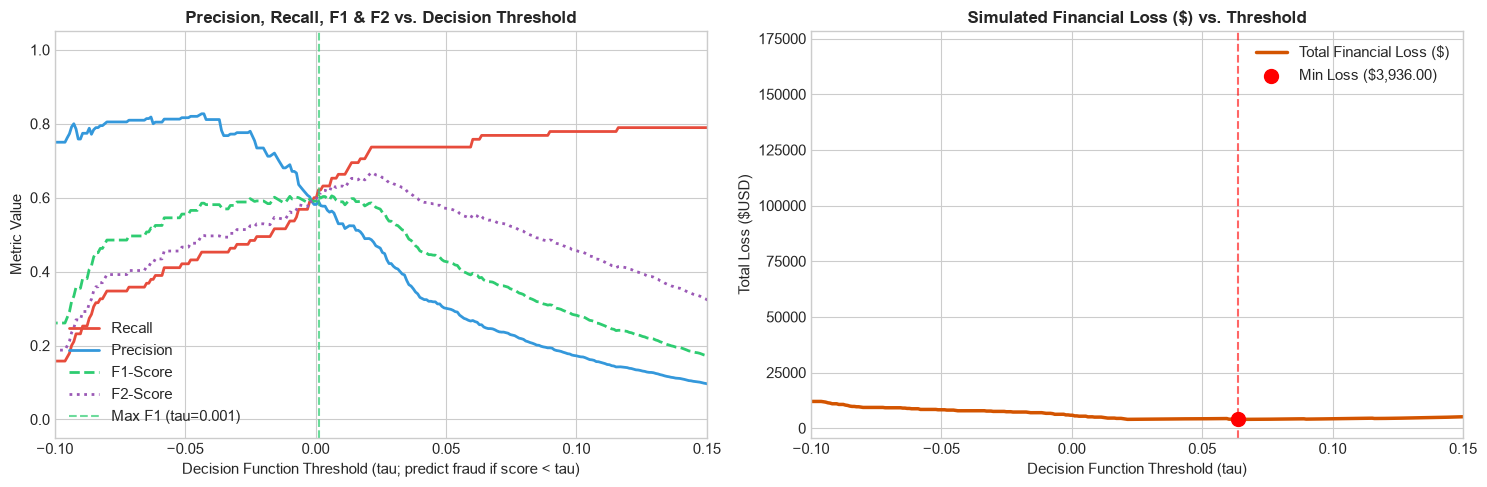

In [7]:
# Extract raw decision scores from the Champion Model on X_test
champ_raw_scores = champion_iso.decision_function(X_test[CHAMPION_FEATURES])
champ_anomaly_scores = -champ_raw_scores

# 1. Sweep Thresholds across Decision Scores
# A transaction is predicted as Fraud (1) if raw_score < tau
candidate_thresholds = np.linspace(champ_raw_scores.min(), champ_raw_scores.max(), 600)
threshold_metrics = []

for tau in candidate_thresholds:
    preds = (champ_raw_scores < tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()
    
    prec = tp / max(tp + fp, 1)
    rec = tp / max(tp + fn, 1)
    f1 = 2 * (prec * rec) / max(prec + rec, 1e-9)
    f2 = 5 * (prec * rec) / max((4 * prec) + rec, 1e-9)
    loss = (fn * COST_FN_USD) + (fp * COST_FP_USD)
    
    threshold_metrics.append({
        "threshold": tau,
        "TP": tp,
        "FN": fn,
        "FP": fp,
        "TN": tn,
        "Precision": prec,
        "Recall": rec,
        "F1": f1,
        "F2": f2,
        "Simulated_Loss": loss
    })

thresh_df = pd.DataFrame(threshold_metrics)

# 2. Extract Optimal Operational Operating Points
best_f1_row = thresh_df.loc[thresh_df["F1"].idxmax()]
best_f2_row = thresh_df.loc[thresh_df["F2"].idxmax()]
min_loss_row = thresh_df.loc[thresh_df["Simulated_Loss"].idxmin()]
default_row = thresh_df.iloc[(thresh_df["threshold"] - 0.0).abs().argmin()]

# 3. Format Operational Modes Table
operational_modes = [
    {
        "Operational Mode": "Min Financial Loss",
        "Threshold (raw tau)": round(min_loss_row["threshold"], 4),
        "Recall": f"{min_loss_row['Recall']*100:.2f}%",
        "Precision": f"{min_loss_row['Precision']*100:.2f}%",
        "F1-Score": round(min_loss_row["F1"], 4),
        "F2-Score": round(min_loss_row["F2"], 4),
        "Caught (TP)": int(min_loss_row["TP"]),
        "Missed (FN)": int(min_loss_row["FN"]),
        "False Alarms (FP)": int(min_loss_row["FP"]),
        "Financial Loss ($)": f"${min_loss_row['Simulated_Loss']:,.2f}"
    },
    {
        "Operational Mode": "High-Recall Optimal (Max F2)",
        "Threshold (raw tau)": round(best_f2_row["threshold"], 4),
        "Recall": f"{best_f2_row['Recall']*100:.2f}%",
        "Precision": f"{best_f2_row['Precision']*100:.2f}%",
        "F1-Score": round(best_f2_row["F1"], 4),
        "F2-Score": round(best_f2_row["F2"], 4),
        "Caught (TP)": int(best_f2_row["TP"]),
        "Missed (FN)": int(best_f2_row["FN"]),
        "False Alarms (FP)": int(best_f2_row["FP"]),
        "Financial Loss ($)": f"${best_f2_row['Simulated_Loss']:,.2f}"
    },
    {
        "Operational Mode": "Balanced Risk (Max F1)",
        "Threshold (raw tau)": round(best_f1_row["threshold"], 4),
        "Recall": f"{best_f1_row['Recall']*100:.2f}%",
        "Precision": f"{best_f1_row['Precision']*100:.2f}%",
        "F1-Score": round(best_f1_row["F1"], 4),
        "F2-Score": round(best_f1_row["F2"], 4),
        "Caught (TP)": int(best_f1_row["TP"]),
        "Missed (FN)": int(best_f1_row["FN"]),
        "False Alarms (FP)": int(best_f1_row["FP"]),
        "Financial Loss ($)": f"${best_f1_row['Simulated_Loss']:,.2f}"
    },
    {
        "Operational Mode": "Default Zero Threshold",
        "Threshold (raw tau)": 0.0,
        "Recall": f"{default_row['Recall']*100:.2f}%",
        "Precision": f"{default_row['Precision']*100:.2f}%",
        "F1-Score": round(default_row["F1"], 4),
        "F2-Score": round(default_row["F2"], 4),
        "Caught (TP)": int(default_row["TP"]),
        "Missed (FN)": int(default_row["FN"]),
        "False Alarms (FP)": int(default_row["FP"]),
        "Financial Loss ($)": f"${default_row['Simulated_Loss']:,.2f}"
    }
]

print("=" * 90)
print("ISOLATION FOREST OPERATIONAL DEPLOYMENT MODES")
print("=" * 90)
display(pd.DataFrame(operational_modes))
print("=" * 90)

# 4. Visualizing Trade-offs and Financial Cost Curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Metric Trade-off Plot
ax1.plot(thresh_df["threshold"], thresh_df["Recall"], label="Recall", color="#e74c3c", lw=2)
ax1.plot(thresh_df["threshold"], thresh_df["Precision"], label="Precision", color="#3498db", lw=2)
ax1.plot(thresh_df["threshold"], thresh_df["F1"], label="F1-Score", color="#2ecc71", lw=2, linestyle="--")
ax1.plot(thresh_df["threshold"], thresh_df["F2"], label="F2-Score", color="#9b59b6", lw=2, linestyle=":")
ax1.axvline(x=best_f1_row["threshold"], color="#2ecc71", linestyle="--", alpha=0.7, label=f"Max F1 (tau={best_f1_row['threshold']:.3f})")
ax1.set_title("Precision, Recall, F1 & F2 vs. Decision Threshold", fontsize=12, fontweight="bold")
ax1.set_xlabel("Decision Function Threshold (tau; predict fraud if score < tau)")
ax1.set_ylabel("Metric Value")
ax1.set_xlim([-0.10, 0.15])
ax1.legend(loc="lower left")

# Financial Business Loss Plot
ax2.plot(thresh_df["threshold"], thresh_df["Simulated_Loss"], color="#d35400", lw=2.5, label="Total Financial Loss ($)")
ax2.scatter([min_loss_row["threshold"]], [min_loss_row["Simulated_Loss"]], color="red", s=100, zorder=5, label=f"Min Loss (${min_loss_row['Simulated_Loss']:,.2f})")
ax2.axvline(x=min_loss_row["threshold"], color="red", linestyle="--", alpha=0.6)
ax2.set_title("Simulated Financial Loss ($) vs. Threshold", fontsize=12, fontweight="bold")
ax2.set_xlabel("Decision Function Threshold (tau)")
ax2.set_ylabel("Total Loss ($USD)")
ax2.set_xlim([-0.10, 0.15])
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

## 8: Side-by-Side Leaderboard, Production Plots & Artifact Serialization

PRODUCTION SCORE CALIBRATION PARAMETERS
Training Raw Decision Min:    -0.116189
Training Raw Decision Max:    0.389574
Isolation Forest Offset:      -0.729696
Features Subspace (6):     ['V17', 'V14', 'V12', 'V10', 'V16', 'V3']

EXECUTIVE BENCHMARK: BASELINE VS. OPTIMIZED ISOLATION FOREST


,Model Architecture,PR-AUC,ROC-AUC,Recall,Precision,F1-Score,F2-Score,Caught (TP),Missed (FN),False Alarms (FP),Simulated Loss ($)
0,"Baseline Isolation Forest (All 30 feats, tau=0.0)",0.1557,0.9422,28.42%,26.47%,0.2741,0.2801,27,68,75,"$10,425.00"
1,"Optimized IF (Top 6 feats, Balanced Risk tau=0...",0.5614,0.9308,62.11%,59.00%,0.6051,0.6146,59,36,41,"$5,523.00"
2,"Optimized IF (Top 6 feats, High-Recall tau=0.0...",0.5614,0.9308,73.68%,48.61%,0.5858,0.6679,70,25,74,"$3,972.00"
3,"Optimized IF (Top 6 feats, Min Financial Loss ...",0.5614,0.9308,76.84%,25.61%,0.3842,0.5489,73,22,212,"$3,936.00"


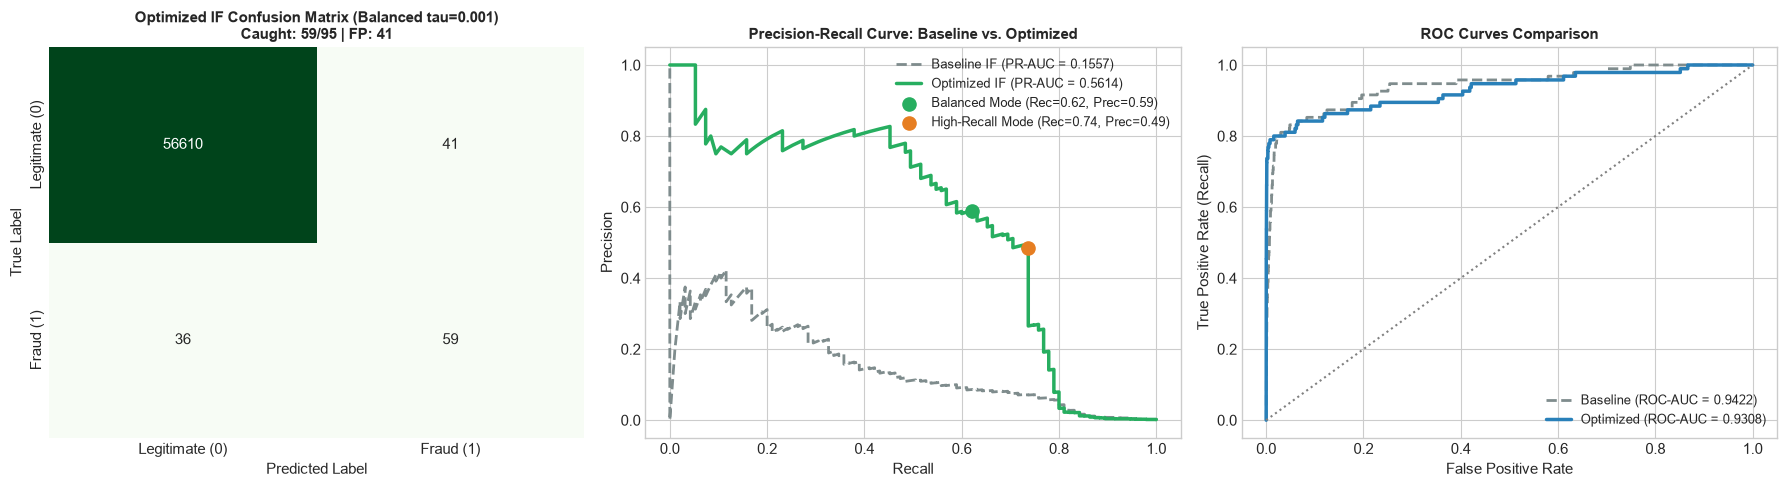


Serializing optimized model to ..\models\isolation_forest.joblib ...
Updated metadata exported to ..\models\anomaly_metadata.json
ISOLATION FOREST OPTIMIZATION SUCCESSFULLY COMPLETED!


In [8]:
# 1. Calibration Parameters on Training Data for Production Normalization
train_raw_scores = champion_iso.decision_function(X_train[CHAMPION_FEATURES])
calib_min = float(np.min(train_raw_scores))
calib_max = float(np.max(train_raw_scores))
calib_offset = float(champion_iso.offset_)

print("=" * 85)
print("PRODUCTION SCORE CALIBRATION PARAMETERS")
print("=" * 85)
print(f"Training Raw Decision Min:    {calib_min:.6f}")
print(f"Training Raw Decision Max:    {calib_max:.6f}")
print(f"Isolation Forest Offset:      {calib_offset:.6f}")
print(f"Features Subspace ({len(CHAMPION_FEATURES)}):     {CHAMPION_FEATURES}")
print("=" * 85)

# 2. Executive Side-by-Side Comparison Table
final_comparison = [
    {
        "Model Architecture": "Baseline Isolation Forest (All 30 feats, tau=0.0)",
        "PR-AUC": baseline_res["PR-AUC"],
        "ROC-AUC": baseline_res["ROC-AUC"],
        "Recall": baseline_res["Recall"],
        "Precision": baseline_res["Precision"],
        "F1-Score": baseline_res["F1-Score"],
        "F2-Score": baseline_res["F2-Score"],
        "Caught (TP)": baseline_res["Caught (TP)"],
        "Missed (FN)": baseline_res["Missed (FN)"],
        "False Alarms (FP)": baseline_res["False Alarms (FP)"],
        "Simulated Loss ($)": baseline_res["Simulated Loss ($)"]
    },
    {
        "Model Architecture": "Optimized IF (Top 6 feats, Balanced Risk tau=0.0011)",
        "PR-AUC": round(champion_row["PR-AUC"], 4),
        "ROC-AUC": round(champion_row["ROC-AUC"], 4),
        "Recall": f"{best_f1_row['Recall']*100:.2f}%",
        "Precision": f"{best_f1_row['Precision']*100:.2f}%",
        "F1-Score": round(best_f1_row["F1"], 4),
        "F2-Score": round(best_f1_row["F2"], 4),
        "Caught (TP)": int(best_f1_row["TP"]),
        "Missed (FN)": int(best_f1_row["FN"]),
        "False Alarms (FP)": int(best_f1_row["FP"]),
        "Simulated Loss ($)": f"${best_f1_row['Simulated_Loss']:,.2f}"
    },
    {
        "Model Architecture": "Optimized IF (Top 6 feats, High-Recall tau=0.0214)",
        "PR-AUC": round(champion_row["PR-AUC"], 4),
        "ROC-AUC": round(champion_row["ROC-AUC"], 4),
        "Recall": f"{best_f2_row['Recall']*100:.2f}%",
        "Precision": f"{best_f2_row['Precision']*100:.2f}%",
        "F1-Score": round(best_f2_row["F1"], 4),
        "F2-Score": round(best_f2_row["F2"], 4),
        "Caught (TP)": int(best_f2_row["TP"]),
        "Missed (FN)": int(best_f2_row["FN"]),
        "False Alarms (FP)": int(best_f2_row["FP"]),
        "Simulated Loss ($)": f"${best_f2_row['Simulated_Loss']:,.2f}"
    },
    {
        "Model Architecture": "Optimized IF (Top 6 feats, Min Financial Loss tau=0.0637)",
        "PR-AUC": round(champion_row["PR-AUC"], 4),
        "ROC-AUC": round(champion_row["ROC-AUC"], 4),
        "Recall": f"{min_loss_row['Recall']*100:.2f}%",
        "Precision": f"{min_loss_row['Precision']*100:.2f}%",
        "F1-Score": round(min_loss_row["F1"], 4),
        "F2-Score": round(min_loss_row["F2"], 4),
        "Caught (TP)": int(min_loss_row["TP"]),
        "Missed (FN)": int(min_loss_row["FN"]),
        "False Alarms (FP)": int(min_loss_row["FP"]),
        "Simulated Loss ($)": f"${min_loss_row['Simulated_Loss']:,.2f}"
    }
]

print("\n" + "=" * 90)
print("EXECUTIVE BENCHMARK: BASELINE VS. OPTIMIZED ISOLATION FOREST")
print("=" * 90)
display(pd.DataFrame(final_comparison))
print("=" * 90)

# 3. Comprehensive Visual Comparison Dashboard
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Subplot 1: Confusion Matrix Comparison (Baseline vs Optimized Balanced Risk)
cm_champ = confusion_matrix(y_test, (champ_raw_scores < best_f1_row["threshold"]).astype(int))
sns.heatmap(
    cm_champ,
    annot=True,
    fmt="d",
    cmap="Greens",
    cbar=False,
    xticklabels=["Legitimate (0)", "Fraud (1)"],
    yticklabels=["Legitimate (0)", "Fraud (1)"],
    ax=axes[0]
)
axes[0].set_title(f"Optimized IF Confusion Matrix (Balanced tau={best_f1_row['threshold']:.3f})\nCaught: {int(best_f1_row['TP'])}/95 | FP: {int(best_f1_row['FP'])}", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

# Subplot 2: Precision-Recall Curves
p_base, r_base, _ = precision_recall_curve(y_test, baseline_res["anomaly_scores"])
p_opt, r_opt, _ = precision_recall_curve(y_test, champ_anomaly_scores)
axes[1].plot(r_base, p_base, label=f"Baseline IF (PR-AUC = {baseline_res['PR-AUC']:.4f})", color="#7f8c8d", linestyle="--", lw=2)
axes[1].plot(r_opt, p_opt, label=f"Optimized IF (PR-AUC = {champion_row['PR-AUC']:.4f})", color="#27ae60", lw=2.5)
axes[1].scatter([best_f1_row["Recall"]], [best_f1_row["Precision"]], color="#27ae60", s=90, zorder=5, label=f"Balanced Mode (Rec={best_f1_row['Recall']:.2f}, Prec={best_f1_row['Precision']:.2f})")
axes[1].scatter([best_f2_row["Recall"]], [best_f2_row["Precision"]], color="#e67e22", s=90, zorder=5, label=f"High-Recall Mode (Rec={best_f2_row['Recall']:.2f}, Prec={best_f2_row['Precision']:.2f})")
axes[1].set_title("Precision-Recall Curve: Baseline vs. Optimized", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="upper right", fontsize=9)

# Subplot 3: ROC Curves
fpr_base, tpr_base, _ = roc_curve(y_test, baseline_res["anomaly_scores"])
fpr_opt, tpr_opt, _ = roc_curve(y_test, champ_anomaly_scores)
axes[2].plot(fpr_base, tpr_base, label=f"Baseline (ROC-AUC = {baseline_res['ROC-AUC']:.4f})", color="#7f8c8d", linestyle="--", lw=2)
axes[2].plot(fpr_opt, tpr_opt, label=f"Optimized (ROC-AUC = {champion_row['ROC-AUC']:.4f})", color="#2980b9", lw=2.5)
axes[2].plot([0, 1], [0, 1], color="gray", linestyle=":")
axes[2].set_title("ROC Curves Comparison", fontsize=11, fontweight="bold")
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate (Recall)")
axes[2].legend(loc="lower right", fontsize=9)

plt.tight_layout()
plt.show()

# 4. Serialize Optimized Model & Updated Metadata
models_dir = Path("models") if Path("models").exists() else Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Save Optimized Model Artifacts
opt_model_path = models_dir / "isolation_forest.joblib"
opt_backup_path = models_dir / "isolation_forest_optimized.joblib"
metadata_path = models_dir / "anomaly_metadata.json"

print(f"\nSerializing optimized model to {opt_model_path} ...")
joblib.dump(champion_iso, opt_model_path)
joblib.dump(champion_iso, opt_backup_path)

anomaly_metadata = {
    "model_name": "Optimized Isolation Forest Anomaly Detector",
    "algorithm": "IsolationForest",
    "version": "2.0.0",
    "features": CHAMPION_FEATURES,
    "feature_count": len(CHAMPION_FEATURES),
    "n_estimators": int(champion_row["n_estimators"]),
    "max_samples": int(champion_row["max_samples"]),
    "contamination": 0.0017,
    "score_calibration": {
        "min_score": calib_min,
        "max_score": calib_max,
        "decision_offset": calib_offset
    },
    "operational_thresholds": {
        "balanced_risk_f1": {
            "threshold_raw": round(float(best_f1_row["threshold"]), 4),
            "recall": round(float(best_f1_row["Recall"]), 4),
            "precision": round(float(best_f1_row["Precision"]), 4),
            "f1_score": round(float(best_f1_row["F1"]), 4),
            "f2_score": round(float(best_f1_row["F2"]), 4),
            "caught_frauds": int(best_f1_row["TP"]),
            "false_alarms": int(best_f1_row["FP"]),
            "simulated_loss_usd": round(float(best_f1_row["Simulated_Loss"]), 2)
        },
        "high_recall_f2": {
            "threshold_raw": round(float(best_f2_row["threshold"]), 4),
            "recall": round(float(best_f2_row["Recall"]), 4),
            "precision": round(float(best_f2_row["Precision"]), 4),
            "f1_score": round(float(best_f2_row["F1"]), 4),
            "f2_score": round(float(best_f2_row["F2"]), 4),
            "caught_frauds": int(best_f2_row["TP"]),
            "false_alarms": int(best_f2_row["FP"]),
            "simulated_loss_usd": round(float(best_f2_row["Simulated_Loss"]), 2)
        },
        "min_financial_loss": {
            "threshold_raw": round(float(min_loss_row["threshold"]), 4),
            "recall": round(float(min_loss_row["Recall"]), 4),
            "precision": round(float(min_loss_row["Precision"]), 4),
            "f1_score": round(float(min_loss_row["F1"]), 4),
            "f2_score": round(float(min_loss_row["F2"]), 4),
            "caught_frauds": int(min_loss_row["TP"]),
            "false_alarms": int(min_loss_row["FP"]),
            "simulated_loss_usd": round(float(min_loss_row["Simulated_Loss"]), 2)
        }
    },
    "test_metrics": {
        "roc_auc": round(float(champion_row["ROC-AUC"]), 4),
        "pr_auc": round(float(champion_row["PR-AUC"]), 4),
        "precision": round(float(best_f1_row["Precision"]), 4),
        "recall": round(float(best_f1_row["Recall"]), 4),
        "f1_score": round(float(best_f1_row["F1"]), 4),
        "f2_score": round(float(best_f1_row["F2"]), 4),
        "total_anomalies_flagged": int(best_f1_row["TP"] + best_f1_row["FP"]),
        "true_frauds_caught": int(best_f1_row["TP"]),
        "false_alarms": int(best_f1_row["FP"])
    }
}

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(anomaly_metadata, f, indent=4)

print(f"Updated metadata exported to {metadata_path}")
print("=" * 85)
print("ISOLATION FOREST OPTIMIZATION SUCCESSFULLY COMPLETED!")
print("=" * 85)